# 05_07 Order Statistics and Extremes: The Smallest, the Largest and the Median

**Learning objectives**
- Derive the **distribution of the $k$-th smallest value** (and of the minimum and maximum) of $n$ independent observations, and recognise it as a **Beta** variable on the probability scale.
- Build **distribution-free confidence intervals** for the median or any quantile from order statistics and the Binomial.
- Know the **asymptotic distribution of the sample median** and why the median shrugs off heavy tails.
- State the **Fisher-Tippett-Gnedenko theorem** (Gumbel, Fréchet, Weibull) and use **return levels** for rare extremes.

**Prerequisites:** [02_04 Beta](../../module_02_continuous/notebooks/02_04_beta.ipynb), [01_01 Bernoulli and Binomial](../../module_01_discrete/notebooks/01_01_bernoulli_binomial.ipynb), [02_07 Laplace, logistic and Gumbel](../../module_02_continuous/notebooks/02_07_laplace_logistic_gumbel.ipynb), [05_03 Sampling distributions and standard error](05_03_sampling_distributions_standard_error.ipynb), [05_04 The bootstrap](05_04_bootstrap_monte_carlo.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- **CDF and quantile function:** $F(x)=P(X\le x)$, $F^{-1}(p)$; **probability integral transform:** if $X$ is continuous then $F(X)\sim\mathrm{Uniform}(0,1)$.
- **Independence:** for iid $X_i$, $P(\text{all}\le x)=F(x)^n$.
- **Binomial:** the number of observations below a fixed value $x$ is $\mathrm{Binomial}(n,F(x))$.
- **Beta($a,b$):** density $\propto u^{a-1}(1-u)^{b-1}$ on $(0,1)$, mean $a/(a+b)$.
- **Sample median and mean** and their standard errors from 05_03; the Cauchy failure of the mean from 05_01.

## 3. Intuition and story

So far we studied **averages**. But some questions are about the **extremes**: the slowest request of the day, the strongest flood of the year, the cheapest bid, the weakest link of a chain. Others are about **positions** in the sorted data: the median, the 95th percentile. All of these are built from the **order statistics**
$$X_{(1)}\le X_{(2)}\le\cdots\le X_{(n)},$$
the sample sorted from smallest to largest.

Two surprises. **(1)** The distribution of *any* order statistic can be written down exactly, and after the transformation $U=F(X)$ it is always a **Beta**, whatever the parent distribution: that gives **confidence intervals for quantiles with no assumptions at all**. **(2)** The *maximum* of many observations does not become Normal; it converges to one of **three** shapes (Gumbel, Fréchet, Weibull), which is the foundation of flood, wind-speed and financial-loss modelling.

## 4. Formal definitions

For iid $X_1,\dots,X_n$ with CDF $F$ and density $f$:

| Quantity | Formula |
|---|---|
| **Maximum** $X_{(n)}$ | $F_{\max}(x)=F(x)^n$, $\;f_{\max}(x)=nF(x)^{n-1}f(x)$ |
| **Minimum** $X_{(1)}$ | $F_{\min}(x)=1-(1-F(x))^n$ |
| **$k$-th order statistic** | $F_{(k)}(x)=\sum_{j=k}^{n}\binom njF(x)^j(1-F(x))^{n-j}$; density $\dfrac{n!}{(k-1)!(n-k)!}F(x)^{k-1}(1-F(x))^{n-k}f(x)$ |
| **Probability scale** | $F(X_{(k)})\sim\mathrm{Beta}(k,\,n-k+1)$, mean $\dfrac k{n+1}$ |
| **Range** $R=X_{(n)}-X_{(1)}$ | for Uniform(0,1): $R\sim\mathrm{Beta}(n-1,2)$ |
| **Distribution-free quantile interval** | $P\big(X_{(l)}\le\xi_p\le X_{(u)}\big)=P\big(l\le B\le u-1\big)$, $B\sim\mathrm{Binomial}(n,p)$ |
| **Sample median (asymptotic)** | $\sqrt n(m-\xi_{0.5})\to N\big(0,\;1/(4f(\xi_{0.5})^2)\big)$ |
| **Extreme-value theorem** | $\dfrac{X_{(n)}-b_n}{a_n}\to G$, the **GEV** family $G_\xi(z)=\exp\{-(1+\xi z)^{-1/\xi}\}$ |
| **Return level** | the value exceeded once per $T$ periods on average: $x_T=F_{\text{period}}^{-1}(1-1/T)$ |

The GEV has three types: $\xi=0$ **Gumbel** (light tails: Normal, Exponential, Gamma), $\xi>0$ **Fréchet** (power-law tails: Pareto, Student $t$, Cauchy), $\xi<0$ **Weibull** (bounded support: Uniform, Beta).

## 5. Derivations

### 5.1 Maximum and minimum
$X_{(n)}\le x$ exactly when *all* $n$ observations are $\le x$; by independence $F(x)^n$. $X_{(1)}>x$ when all are $>x$, so $P(X_{(1)}\le x)=1-(1-F(x))^n$. **In plain words.** The max stays low only if every single draw stays low, which becomes very unlikely as $n$ grows, so the max creeps upward.

### 5.2 The $k$-th order statistic
$X_{(k)}\le x$ exactly when **at least $k$** of the $n$ observations are $\le x$. The count below $x$ is $\mathrm{Binomial}(n,F(x))$, so $F_{(k)}(x)=\sum_{j\ge k}\binom njF^j(1-F)^{n-j}$. Differentiating gives the density $\frac{n!}{(k-1)!(n-k)!}F^{k-1}(1-F)^{n-k}f$: one observation at $x$, $k-1$ below, $n-k$ above, and the multinomial count in front. **In plain words.** Where the $k$-th value lands is decided by how many points fall below a given spot, a Binomial question.

### 5.3 Why it is a Beta on the probability scale
Put $U_i=F(X_i)\sim\mathrm{Uniform}(0,1)$; order statistics commute with the increasing map $F$. For the uniform, $F=u$ and the density above is $\frac{n!}{(k-1)!(n-k)!}u^{k-1}(1-u)^{n-k}$, the $\mathrm{Beta}(k,n-k+1)$ density. Hence $E[F(X_{(k)})]=\frac k{n+1}$ (the $k$-th point sits about $k/(n+1)$ of the way through the probability), and the regularised incomplete Beta function equals the Binomial sum of 5.2. **In plain words.** The sorted sample cuts the probability scale into $n+1$ pieces of equal expected size: that is why the plotting positions $k/(n+1)$ appear in Q-Q plots.

### 5.4 Distribution-free confidence interval for a quantile
The quantile $\xi_p$ satisfies $F(\xi_p)=p$. It lies in $[X_{(l)},X_{(u)}]$ exactly when the number of observations below $\xi_p$, which is $\mathrm{Binomial}(n,p)$, is between $l$ and $u-1$. So the coverage is $P(l\le B\le u-1)$ **whatever $F$ is** (continuous). **In plain words.** Count how many data points fall below the true median: it must be Binomial(n, 1/2), and we pick the two ranks that trap that count 95 % of the time.

### 5.5 Median variance (asymptotic)
$\#\{X_i\le\xi+t/\sqrt n\}\approx n\big(p+f(\xi)t/\sqrt n\big)$; matching to the Binomial's spread $\sqrt{np(1-p)}$ gives $\mathrm{Var}(m)\approx\dfrac{p(1-p)}{n f(\xi)^2}$, which for the median is $\dfrac1{4nf(\xi)^2}$. For $N(0,\sigma^2)$: $f(0)=1/(\sigma\sqrt{2\pi})$, so $\mathrm{Var}(m)=\dfrac{\pi\sigma^2}{2n}$: the median is $\pi/2=1.57$ times as variable as the mean (efficiency 64 %). For the Laplace the median beats the mean; for the Cauchy the median works while the mean does not. **In plain words.** The median's precision depends on how crowded the data are right around it.

### 5.6 The Gumbel limit for an Exponential parent
For Exponential(1), $P(X_{(n)}-\ln n\le z)=(1-e^{-z}/n)^n\to\exp(-e^{-z})$, the **Gumbel** CDF. **In plain words.** The max of $n$ exponentials is about $\ln n$ plus a Gumbel wobble: doubling the sample size adds only $\ln2=0.69$ to the typical maximum.

### 5.7 Return level
If the annual maximum has CDF $F_A$, the $T$-year return level solves $F_A(x_T)=1-1/T$. For Gumbel$(\mu,\beta)$: $x_T=\mu-\beta\ln(-\ln(1-1/T))$. **In plain words.** A "100-year flood" is the level with a 1 % chance of being exceeded in any given year, not a flood that comes once per century.

## 6. Properties and relationships

- **Relation to the Beta (02_04) and Binomial (01_02):** $F(X_{(k)})\sim\mathrm{Beta}(k,n-k+1)$ and $P(X_{(k)}\le x)=P(\mathrm{Bin}(n,F(x))\ge k)$; the two are the same identity.
- **Exponential spacings (Rényi):** for Exponential(1), $X_{(k)}=\sum_{i=1}^k\frac{Z_i}{n-i+1}$ with iid Exponential(1) $Z_i$: the gaps are independent exponentials, which gives $E[X_{(n)}]=\sum_{i=1}^n1/i\approx\ln n+0.577$.
- **Max of $n$ standard Normals:** grows like $\sqrt{2\ln n}$, extremely slowly, and approaches that rule from below (for $n=1{,}000$ the expected maximum is 3.24 while $\sqrt{2\ln n}=3.72$); the *spread* of the maximum shrinks like $1/\sqrt{2\ln n}$.
- **Maximum is not a smooth statistic:** bootstrap fails (05_04); use the exact formulas, extreme-value theory, or a parametric model.
- **Heavy tails:** for a Pareto$(\alpha)$ the max grows like $n^{1/\alpha}$: a single observation can dominate the sum.
- **Median versus mean:** the median is always finite and robust; its variance depends on the density at the centre, not on the tails.

## 7. 2D visuals

### 7.1 All ten order statistics of ten uniform draws
The $k$-th smallest of $n=10$ Uniform(0,1) values has the Beta($k$, $11-k$) density; the bars are 50,000 simulated samples. The ten bumps share the interval evenly, centred at $k/11$.

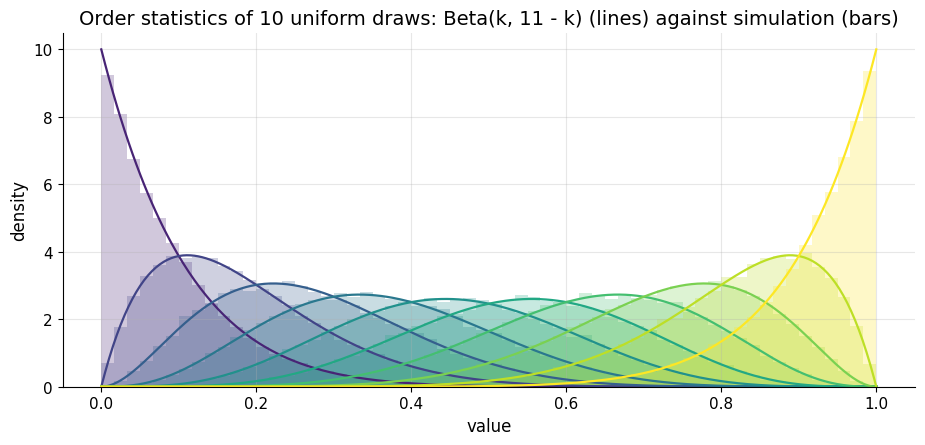

In [2]:
n = 10
U = np.sort(rng.uniform(size=(50_000, n)), axis=1)
u = np.linspace(0, 1, 400)
fig, ax = plt.subplots(figsize=(11, 4.6))
cmap = plt.get_cmap("viridis")
for k in range(1, n + 1):
    ax.hist(U[:, k - 1], bins=60, range=(0, 1), density=True, color=cmap(k / n), alpha=0.25)
    ax.plot(u, stats.beta(k, n - k + 1).pdf(u), color=cmap(k / n), linewidth=1.6)
ax.set_title("Order statistics of 10 uniform draws: Beta(k, 11 - k) (lines) against simulation (bars)")
ax.set_xlabel("value"); ax.set_ylabel("density")
plt.show()
assert np.allclose(U.mean(axis=0), np.arange(1, n + 1) / (n + 1), atol=0.004)

### 7.2 The maximum creeps up like ln(n)
Max of $n$ Exponential(mean 1) values: the CDF $(1-e^{-x})^n$ moves right by $\ln n$ each time $n$ is multiplied by $e$, with a Gumbel shape. Left: densities for several $n$; right: after subtracting $\ln n$ they collapse onto the Gumbel curve.

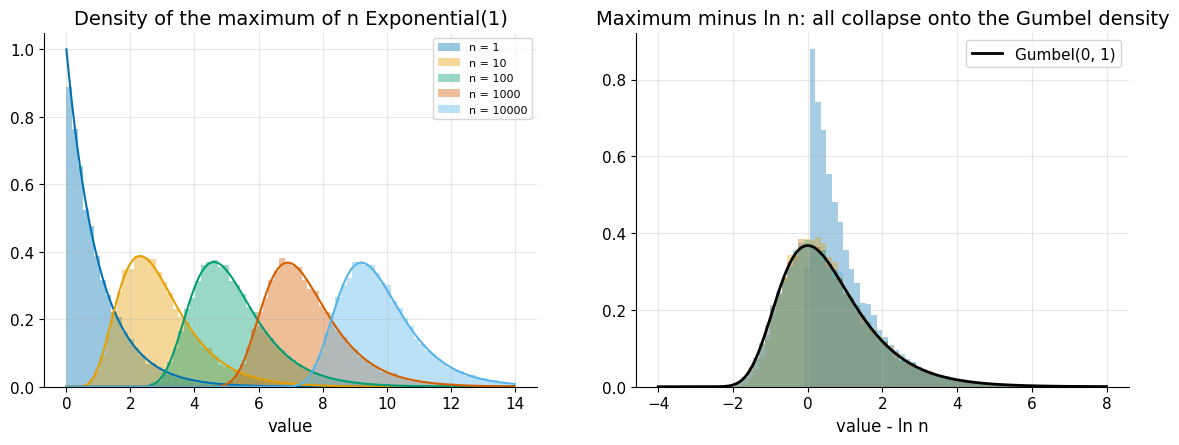

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
x = np.linspace(0, 14, 500)
for nn, c in zip([1, 10, 100, 1000, 10000], COLORS):
    mx = -np.log(1 - rng.uniform(size=20_000) ** (1 / nn))                 # exact draw of the maximum of nn Exponential(1) values
    axes[0].hist(mx, bins=80, range=(0, 14), density=True, color=c, alpha=0.4, label=f"n = {nn}")
    axes[0].plot(x, nn * (1 - np.exp(-x)) ** (nn - 1) * np.exp(-x), color=c)
    axes[1].hist(mx - np.log(nn), bins=80, range=(-4, 8), density=True, color=c, alpha=0.35)
z = np.linspace(-4, 8, 300)
axes[1].plot(z, stats.gumbel_r.pdf(z), color="black", linewidth=2, label="Gumbel(0, 1)")
axes[0].set_title("Density of the maximum of n Exponential(1)"); axes[0].set_xlabel("value"); axes[0].legend(fontsize=8)
axes[1].set_title("Maximum minus ln n: all collapse onto the Gumbel density"); axes[1].set_xlabel("value - ln n"); axes[1].legend()
plt.show()

### 7.3 The maximum of n standard Normals grows only like sqrt(2 ln n)
Expected maximum against $\sqrt{2\ln n}$: the simple rule is only the first-order asymptote and overshoots (3.72 against 3.24 at $n=1{,}000$) because convergence is slow; the spread of the maximum shrinks.

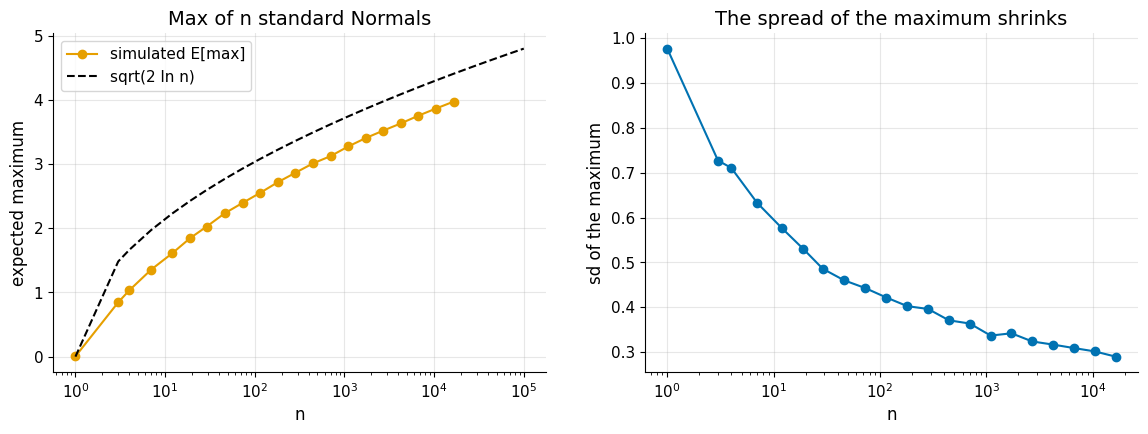

E[max of 1000 standard Normals]: simulated 3.24 | sqrt(2 ln n) = 3.717


In [4]:
ns = np.unique(np.logspace(0.3, 5, 25).astype(int))
mean_max = [rng.normal(size=(2000, nn)).max(axis=1).mean() if nn <= 20_000 else np.nan for nn in ns]
sd_max = [rng.normal(size=(2000, nn)).max(axis=1).std() if nn <= 20_000 else np.nan for nn in ns]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
axes[0].semilogx(ns, mean_max, "o-", color=SIM, label="simulated E[max]")
axes[0].semilogx(ns, np.sqrt(2 * np.log(ns)), "--", color="black", label="sqrt(2 ln n)")
axes[0].set_xlabel("n"); axes[0].set_ylabel("expected maximum"); axes[0].legend(); axes[0].set_title("Max of n standard Normals")
axes[1].semilogx(ns, sd_max, "o-", color=MAIN); axes[1].set_xlabel("n"); axes[1].set_ylabel("sd of the maximum"); axes[1].set_title("The spread of the maximum shrinks")
plt.show()
print("E[max of 1000 standard Normals]: simulated", round(rng.normal(size=(5000, 1000)).max(axis=1).mean(), 3), "| sqrt(2 ln n) =", round(np.sqrt(2 * np.log(1000)), 3))

### 7.4 The median against the mean for three parents
SE of the sample median and of the mean as $n$ grows, for Normal, Laplace and Cauchy data. Normal: the mean wins (the median's variance is $\pi/2=1.57$ times larger, its spread 1.25 times). Laplace: the median wins (spread ratio about 1.4). Cauchy: the mean never settles (05_01) and the median converges.

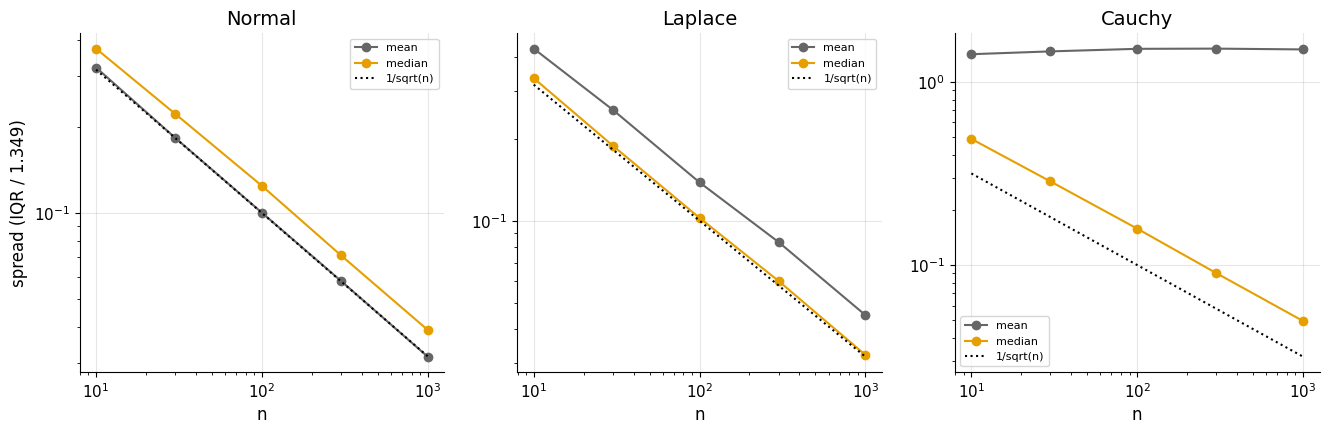

 parent  mean / median spread at n = 1000
 Normal                             0.807
Laplace                             1.401
 Cauchy                            30.355


In [5]:
ns_ = [10, 30, 100, 300, 1000]
parents = {"Normal": lambda size: rng.normal(size=size), "Laplace": lambda size: rng.laplace(size=size), "Cauchy": lambda size: rng.standard_cauchy(size=size)}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
se_table = []
for ax, (name, draw) in zip(axes, parents.items()):
    sm, smed = [], []
    for nn in ns_:
        d = draw((8000, nn))
        sm.append(np.subtract(*np.percentile(d.mean(axis=1), [75, 25])) / 1.349)          # robust spread, because the Cauchy mean has no SD
        smed.append(np.subtract(*np.percentile(np.median(d, axis=1), [75, 25])) / 1.349)
    ax.loglog(ns_, sm, "o-", color=NEUTRAL, label="mean"); ax.loglog(ns_, smed, "o-", color=SIM, label="median")
    ax.loglog(ns_, 1 / np.sqrt(ns_), "k:", label="1/sqrt(n)"); ax.set_title(name); ax.set_xlabel("n"); ax.legend(fontsize=8)
    se_table.append({"parent": name, "mean / median spread at n = 1000": sm[-1] / smed[-1]})
axes[0].set_ylabel("spread (IQR / 1.349)")
plt.show()
print(pd.DataFrame(se_table).round(3).to_string(index=False))

### 7.5 Three types of extremes
The maximum of $n=500$ values from Exponential (light tail), Pareto with $\alpha=3$ (power-law tail) and Uniform (bounded), each shifted and scaled, against the Gumbel, Fréchet and Weibull limits. The shape parameter of the GEV fit has the sign predicted by theory.

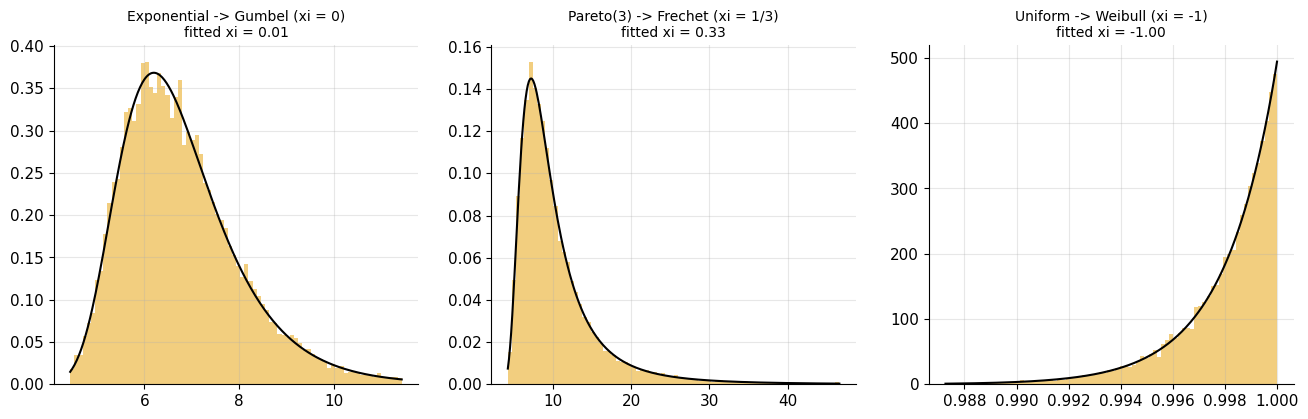

{'Exponential -> Gumbel (xi = 0)': np.float64(0.01), 'Pareto(3) -> Frechet (xi = 1/3)': np.float64(0.33), 'Uniform -> Weibull (xi = -1)': np.float64(-1.001)}


In [6]:
nn, reps = 500, 20_000
cases = {
    "Exponential -> Gumbel (xi = 0)": (rng.exponential(size=(reps, nn)).max(axis=1), 0.0),
    "Pareto(3) -> Frechet (xi = 1/3)": (rng.pareto(3, size=(reps, nn)).max(axis=1) + 1, 1 / 3),
    "Uniform -> Weibull (xi = -1)": (rng.uniform(size=(reps, nn)).max(axis=1), -1.0),
}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
fits = {}
for ax, (name, (mx, xi_true)) in zip(axes, cases.items()):
    c_, loc, scale = stats.genextreme.fit(mx)
    xi_hat = -c_                                                     # scipy's c is minus the usual shape
    fits[name] = xi_hat
    xs = np.linspace(np.percentile(mx, 0.2), np.percentile(mx, 99.5), 300)
    ax.hist(mx, bins=80, density=True, color=SIM, alpha=0.5, range=(xs[0], xs[-1]))
    ax.plot(xs, stats.genextreme.pdf(xs, c_, loc, scale), color="black")
    ax.set_title(f"{name}\nfitted xi = {xi_hat:.2f}", fontsize=10)
plt.show()
print({k: round(v, 3) for k, v in fits.items()})

## 8. 3D visuals

### 8.1 Static: the joint density of the minimum and maximum
For $n=5$ Uniform(0,1) draws the pair $(X_{(1)},X_{(n)})$ has density $n(n-1)(y-x)^{n-2}$ on $0<x<y<1$: a ridge rising toward the far corner (small minimum, large maximum), with all the mass above the diagonal. Points are 500 simulated samples.

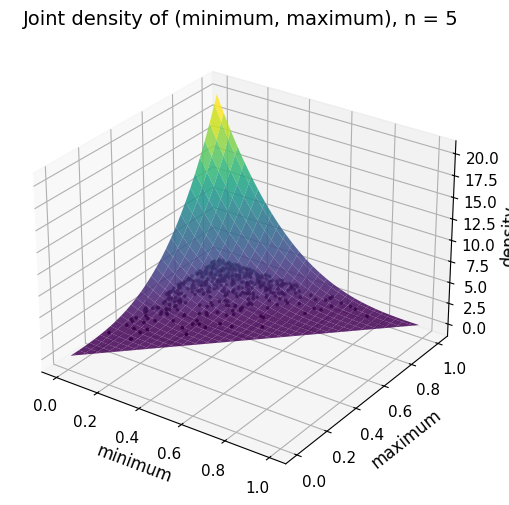

range of 5 uniforms: simulated mean 0.668 | Beta(n-1, 2) mean 0.667


In [7]:
n5 = 5
gx = np.linspace(0, 1, 60)
Xg, Yg = np.meshgrid(gx, gx)
Zg = np.where(Yg > Xg, n5 * (n5 - 1) * np.clip(Yg - Xg, 0, None) ** (n5 - 2), np.nan)
sam = np.sort(rng.uniform(size=(500, n5)), axis=1)
fig = plt.figure(figsize=(8.5, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Xg, Yg, Zg, cmap="viridis", edgecolor="none", alpha=0.85)
ax.scatter(sam[:, 0], sam[:, -1], 0, color="black", s=3)
ax.set_title("Joint density of (minimum, maximum), n = 5"); ax.set_xlabel("minimum"); ax.set_ylabel("maximum"); ax.set_zlabel("density")
ax.view_init(elev=28, azim=-55)
plt.show()
rng_ = sam[:, -1] - sam[:, 0]
print("range of 5 uniforms: simulated mean", round(rng_.mean(), 3), "| Beta(n-1, 2) mean", round(stats.beta(n5 - 1, 2).mean(), 3))
assert abs(rng_.mean() - 2 / 3) < 0.02

### 8.2 Static: $P(\max>x)$ over $(n,x)$
For Exponential(mean 50 ms) latencies: $1-(1-e^{-x/50})^n$. The surface rises from 0 to 1 along a diagonal valley: to keep the same exceedance risk, the threshold must grow like $50\ln n$.

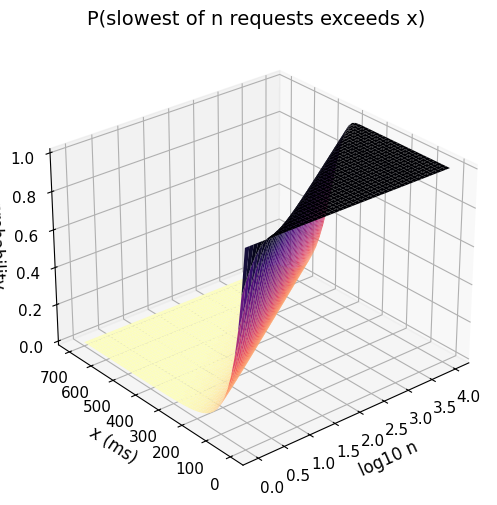

In [8]:
n_ax = np.logspace(0, 4, 50)
x_ax = np.linspace(0, 700, 50)
Pg = 1 - (1 - np.exp(-x_ax[:, None] / 50)) ** n_ax[None, :]
Ng, Xg2 = np.meshgrid(np.log10(n_ax), x_ax)
fig = plt.figure(figsize=(8.5, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Ng, Xg2, Pg, cmap="magma_r", edgecolor="none")
ax.set_title("P(slowest of n requests exceeds x)"); ax.set_xlabel("log10 n"); ax.set_ylabel("x (ms)"); ax.set_zlabel("probability")
ax.view_init(elev=28, azim=-130)
plt.show()

### 8.3 Interactive Plotly version of 8.2
Hover to read the exceedance probability for any $(n,x)$.

In [9]:
fig = go.Figure(go.Surface(x=n_ax, y=x_ax, z=Pg, colorscale="Magma", reversescale=True))
fig.update_layout(title="P(max latency > x)", width=750, height=550, scene=dict(xaxis_title="n requests", yaxis_title="x (ms)", zaxis_title="probability", xaxis_type="log"))
fig.show()

## 9. Simulation vs theory

### 9.1 Every order statistic is Beta on the probability scale (any parent)
For three very different parents (Exponential, Lognormal, Normal), compute $F(X_{(k)})$ for $n=12$ and test it against $\mathrm{Beta}(k,13-k)$ with a Kolmogorov-Smirnov test, for each $k$. The smallest p-value over the 36 tests should look like what 36 genuine tests give (not small).

In [10]:
n = 12
parents = {"Exponential": stats.expon(), "Lognormal": stats.lognorm(0.8), "Normal": stats.norm()}
pvals = []
for name, dist in parents.items():
    xs_s = np.sort(dist.rvs((20_000, n), random_state=rng), axis=1)
    for k in range(1, n + 1):
        pvals.append((name, k, stats.kstest(dist.cdf(xs_s[:, k - 1]), stats.beta(k, n - k + 1).cdf).pvalue))
pv = pd.DataFrame(pvals, columns=["parent", "k", "p"])
print("smallest KS p-value over", len(pv), "tests:", round(pv.p.min(), 4), "| median p-value:", round(pv.p.median(), 3))
assert pv.p.min() > 0.0005

smallest KS p-value over 36 tests: 0.0274 | median p-value: 0.532


### 9.2 Median variance: simulation against $1/(4nf^2)$
For four parents the simulated variance of the sample median (n = 101) against the asymptotic formula $1/(4nf(\xi)^2)$.

In [11]:
n = 101
cases = {"Normal(0,1)": (stats.norm(), 0.0), "Logistic(0,1)": (stats.logistic(), 0.0), "Exponential(1)": (stats.expon(), np.log(2)), "Student t(5)": (stats.t(5), 0.0)}
rows = []
for name, (dist, med) in cases.items():
    meds = np.median(dist.rvs((60_000, n), random_state=rng), axis=1)
    rows.append({"parent": name, "simulated var": meds.var(), "1/(4 n f(median)^2)": 1 / (4 * n * dist.pdf(med) ** 2)})
vt = pd.DataFrame(rows); vt["ratio"] = vt["simulated var"] / vt["1/(4 n f(median)^2)"]
print(vt.round(5).to_string(index=False))
assert vt["ratio"].between(0.9, 1.1).all()

        parent  simulated var  1/(4 n f(median)^2)   ratio
   Normal(0,1)        0.01535              0.01555 0.98668
 Logistic(0,1)        0.03956              0.03960 0.99880
Exponential(1)        0.00996              0.00990 1.00586
  Student t(5)        0.01711              0.01718 0.99617


### 9.3 Gumbel convergence: how fast is the maximum of Exponential(1)?
Kolmogorov distance between the CDF of $X_{(n)}-\ln n$ and the Gumbel CDF, exactly: $\sup_z|(1-e^{-z}/n)^n-\exp(-e^{-z})|\approx\frac{2}{e^2n}$.

In [12]:
z = np.linspace(-3, 12, 4000)
rows = []
for nn in [2, 5, 10, 50, 100, 1000, 10_000]:
    exact_cdf = np.where(z > -np.log(nn), (1 - np.exp(-z) / nn) ** nn, 0.0)
    rows.append({"n": nn, "sup |exact - Gumbel|": np.max(np.abs(exact_cdf - stats.gumbel_r.cdf(z))), "2/(e^2 n)": 2 / (np.e ** 2 * nn)})
gum = pd.DataFrame(rows); print(gum.round(5).to_string(index=False))
assert (gum["sup |exact - Gumbel|"] / gum["2/(e^2 n)"]).iloc[3:].between(0.8, 1.3).all()

    n  sup |exact - Gumbel|  2/(e^2 n)
    2               0.16190    0.13534
    5               0.05799    0.05413
   10               0.02800    0.02707
   50               0.00545    0.00541
  100               0.00272    0.00271
 1000               0.00027    0.00027
10000               0.00003    0.00003


## 10. `scipy.stats` and NumPy cheat sheet for this lesson

In [13]:
x = np.array([7.1, 3.4, 9.9, 4.8, 6.0, 5.2, 8.3])
print("sorted sample (order statistics): np.sort(x) ->", np.sort(x), "| k-th smallest: np.partition(x, 2)[2] ->", np.partition(x, 2)[2])
print("Beta of the k-th order statistic (k = 3, n = 7): stats.beta(3, 5).mean() ->", round(stats.beta(3, 5).mean(), 4), "= k/(n+1) =", 3 / 8)
print("P(max of 1000 Exponential(50) > 500): 1 - (1 - exp(-10))^1000 =", round(1 - (1 - np.exp(-10)) ** 1000, 5))
print("ranks for the median CI, n = 60: lower rank l = stats.binom(60, 0.5).ppf(0.025) ->", int(stats.binom(60, 0.5).ppf(0.025)), "| upper rank u = ppf(0.975) + 1 ->", int(stats.binom(60, 0.5).ppf(0.975)) + 1)
print("Gumbel, GEV: stats.gumbel_r(loc, scale), stats.genextreme(c, loc, scale)  (scipy c = -xi); fit: stats.genextreme.fit(maxima)")
print("return level (T = 100): stats.genextreme(c, loc, scale).isf(1 / 100) -> for the standard Gumbel:", round(stats.gumbel_r.isf(0.01), 4), "= -ln(-ln(0.99)) =", round(-np.log(-np.log(0.99)), 4))
print("confidence interval for a quantile directly (SciPy 1.10+): stats.bootstrap, or the Binomial recipe of Example 2")

sorted sample (order statistics): np.sort(x) -> [3.4 4.8 5.2 6.  7.1 8.3 9.9] | k-th smallest: np.partition(x, 2)[2] -> 5.2
Beta of the k-th order statistic (k = 3, n = 7): stats.beta(3, 5).mean() -> 0.375 = k/(n+1) = 0.375
P(max of 1000 Exponential(50) > 500): 1 - (1 - exp(-10))^1000 = 0.04439
ranks for the median CI, n = 60: lower rank l = stats.binom(60, 0.5).ppf(0.025) -> 22 | upper rank u = ppf(0.975) + 1 -> 39
Gumbel, GEV: stats.gumbel_r(loc, scale), stats.genextreme(c, loc, scale)  (scipy c = -xi); fit: stats.genextreme.fit(maxima)
return level (T = 100): stats.genextreme(c, loc, scale).isf(1 / 100) -> for the standard Gumbel: 4.6001 = -ln(-ln(0.99)) = 4.6001
confidence interval for a quantile directly (SciPy 1.10+): stats.bootstrap, or the Binomial recipe of Example 2


## 11. Real-world worked examples

---
### Example 1 (main): the slowest of 1,000 requests

**Scenario.** A web service has Exponential response times with mean **50 ms**. A page load makes **$n=1{,}000$** independent requests and is as slow as its **slowest** request. The product team wants a hard limit of 500 ms for the page.

**Questions**
1. What is the probability that the slowest request exceeds **500 ms**?
2. What are the **median** and the **mean** of the slowest request?
3. What threshold keeps the chance of breaching it below **1 %**?
4. How good is the **Gumbel approximation** $x\approx50(\ln n+G)$, $G\sim$ Gumbel, for Questions 1 and 3?

### 11.1 By hand
Let $F(x)=1-e^{-x/50}$ and $M=X_{(1000)}$.

**Q1.** $P(M>500)=1-F(500)^{1000}=1-(1-e^{-10})^{1000}=1-(1-4.54\times10^{-5})^{1000}\approx1-e^{-0.0454}=0.0444$.

**Q2.** Median: $F(x)^{1000}=0.5\Rightarrow x=-50\ln\big(1-0.5^{1/1000}\big)=-50\ln(6.93\times10^{-4})=50\times7.274=363.7$ ms. Mean (Rényi): $E[M]=50\sum_{i=1}^{1000}1/i=50\times7.4855=374.3$ ms.

**Q3.** $F(x)^{1000}=0.99\Rightarrow1-e^{-x/50}=0.99^{1/1000}\Rightarrow x=-50\ln\big(1-0.99^{1/1000}\big)=-50\ln(1.005\times10^{-5})=575.4$ ms.

**Q4.** Gumbel: $M\approx50(\ln1000+G)$ with $\ln1000=6.908$, so the $q$-quantile is $50(6.908-\ln(-\ln q))$: median $50(6.908+0.3665)=363.7$, 99th percentile $50(6.908+4.600)=575.4$.

In [14]:
mean_ms, n_req = 50.0, 1000
cdf = lambda x: 1 - np.exp(-x / mean_ms)
p_breach = 1 - cdf(500) ** n_req
med_max = -mean_ms * np.log(1 - 0.5 ** (1 / n_req))
mean_max = mean_ms * np.sum(1 / np.arange(1, n_req + 1))
q99 = -mean_ms * np.log(1 - 0.99 ** (1 / n_req))
print(f"Q1: P(max > 500 ms) = {p_breach:.4f}")
print(f"Q2: median of the max {med_max:.1f} ms, mean {mean_max:.1f} ms")
print(f"Q3: threshold with 1% breach risk: {q99:.1f} ms")
gum_med = mean_ms * (np.log(n_req) - np.log(-np.log(0.5))); gum_q99 = mean_ms * (np.log(n_req) - np.log(-np.log(0.99)))
gum_p = 1 - np.exp(-np.exp(-(500 / mean_ms - np.log(n_req))))
print(f"Q4: Gumbel: P(max > 500) {gum_p:.4f}, median {gum_med:.1f}, 99th percentile {gum_q99:.1f}")

Q1: P(max > 500 ms) = 0.0444
Q2: median of the max 363.7 ms, mean 374.3 ms
Q3: threshold with 1% breach risk: 575.4 ms
Q4: Gumbel: P(max > 500) 0.0444, median 363.7, 99th percentile 575.4


### 11.2 In code with `scipy`, and the asserts

In [15]:
from scipy.special import digamma
assert abs(p_breach - 0.0444) < 5e-4 and abs(med_max - 363.7) < 0.2 and abs(mean_max - 374.3) < 0.2 and abs(q99 - 575.4) < 0.3
assert abs(gum_med - med_max) < 0.2 and abs(gum_q99 - q99) < 0.5 and abs(gum_p - p_breach) < 5e-4
mx_dist = stats.expon(scale=mean_ms)
assert abs((mx_dist.cdf(q99) ** n_req) - 0.99) < 1e-9                       # q99 solves F(x)^n = 0.99
assert abs(mean_max - mean_ms * (digamma(n_req + 1) + np.euler_gamma)) < 1e-9   # harmonic number H_n = digamma(n + 1) + gamma
print("all checks passed")

all checks passed


### 11.3 Verify by simulation
Simulate 20,000 page loads of 1,000 requests each and compare the breach rate, the median and mean of the slowest request and its 99th percentile.

In [16]:
sim_rng = np.random.default_rng(71)
mx_sim = sim_rng.exponential(mean_ms, (20_000, n_req)).max(axis=1)
print(f"P(max > 500): simulated {np.mean(mx_sim > 500):.4f} (theory {p_breach:.4f}) | median {np.median(mx_sim):.1f} ({med_max:.1f}) | mean {mx_sim.mean():.1f} ({mean_max:.1f}) | 99th percentile {np.percentile(mx_sim, 99):.1f} ({q99:.1f})")
assert abs(np.mean(mx_sim > 500) - p_breach) < 0.004 and abs(np.median(mx_sim) - med_max) < 3 and abs(mx_sim.mean() - mean_max) < 3 and abs(np.percentile(mx_sim, 99) - q99) < 12

P(max > 500): simulated 0.0453 (theory 0.0444) | median 364.1 (363.7) | mean 374.4 (374.3) | 99th percentile 571.0 (575.4)


### 11.4 Plots with the regions shaded

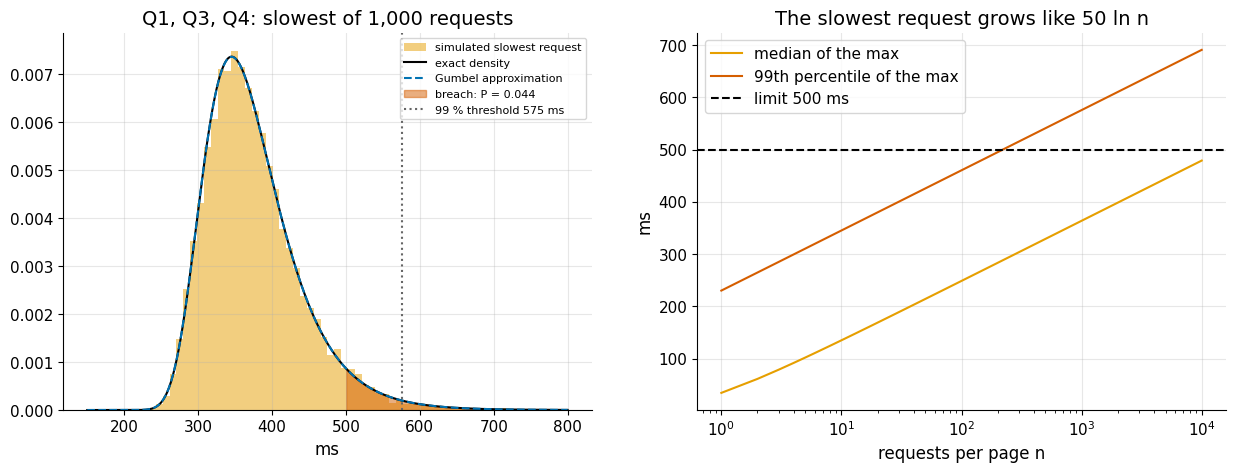

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.9))
xs = np.linspace(150, 800, 500)
dens = n_req * cdf(xs) ** (n_req - 1) * np.exp(-xs / mean_ms) / mean_ms
axes[0].hist(mx_sim, bins=70, density=True, color=SIM, alpha=0.5, range=(150, 800), label="simulated slowest request")
axes[0].plot(xs, dens, color="black", label="exact density")
axes[0].plot(xs, stats.gumbel_r.pdf(xs, loc=mean_ms * np.log(n_req), scale=mean_ms), color=MAIN, linestyle="--", label="Gumbel approximation")
axes[0].fill_between(xs, 0, dens, where=xs >= 500, color=HIGHLIGHT, alpha=0.5, label=f"breach: P = {p_breach:.3f}")
axes[0].axvline(q99, color=NEUTRAL, linestyle=":", label=f"99 % threshold {q99:.0f} ms")
axes[0].set_title("Q1, Q3, Q4: slowest of 1,000 requests"); axes[0].set_xlabel("ms"); axes[0].legend(fontsize=8)
ns_ = np.unique(np.logspace(0, 4, 40).astype(int))
axes[1].semilogx(ns_, -mean_ms * np.log(1 - 0.5 ** (1 / ns_)), color=SIM, label="median of the max")
axes[1].semilogx(ns_, -mean_ms * np.log(1 - 0.99 ** (1 / ns_)), color=HIGHLIGHT, label="99th percentile of the max")
axes[1].axhline(500, color="black", linestyle="--", label="limit 500 ms"); axes[1].set_xlabel("requests per page n"); axes[1].set_ylabel("ms"); axes[1].legend()
axes[1].set_title("The slowest request grows like 50 ln n")
plt.show()

### 11.5 Interpretation and decision (Example 1)
- **A tiny per-request risk becomes a real page risk.** One request exceeds 500 ms with probability $e^{-10}=4.5\times10^{-5}$ (1 in 22,000), but a page with 1,000 requests breaches the limit with probability **4.4 %**: about 1 page in 23.
- **The slowest request is far above the average one.** Its median is **364 ms** and its mean 374 ms, about **7.3 times** the mean latency of 50 ms, because the maximum of $n$ exponentials sits near $\text{mean}\times\ln n$.
- **Setting limits.** To keep breaches below 1 % the limit must be **575 ms**; alternatively, to keep the 500 ms limit with 1 % risk each request's mean latency must be about $500/11.5=43$ ms. Doubling the number of requests per page adds only $50\ln2=35$ ms to the typical slowest request.
- **Approximation and simulation.** The Gumbel formula reproduces the exact values to three digits; the simulation (20,000 pages) gives 4.5 % and a 99th percentile of 571 ms, within Monte Carlo error of 575 ms.
- **Decision.** Set the page budget from the **maximum**, not from the average or from a single request's percentile: either cut requests per page (fan-out), or give each service a tail target near its 99.99th percentile.

---
### Example 2: a confidence interval for the median with no assumptions

**Scenario.** Sixty delivery times (the skewed Gamma population of 05_03 and 05_04, a fresh sample) were recorded. We want a 95 % confidence interval for the **median** and for the **90th percentile**, using only the sorted data (no Normal assumption, no resampling).

### 11.6 By hand, in code and by simulation
**By hand.** For the median the count below $\xi$ is Binomial(60, 0.5) with mean 30 and SD 3.87. The interval $[X_{(l)},X_{(u)}]$ has coverage $P(l\le B\le u-1)$. Taking $l=22$ and $u=39$ (symmetric around the middle rank 30.5) gives $1-2P(B\le21)=0.973$. Shifting one rank, $(22,38)$, gives 0.960, and the next shorter symmetric pair $(23,38)$ only 0.948, which is below 95 %. For the 90th percentile the count is Binomial(60, 0.9), mean 54, SD 2.32.

In [18]:
pop = np.random.default_rng(2025).gamma(shape=4, scale=7.5, size=20_000)
samp = np.sort(np.random.default_rng(77).choice(pop, 60, replace=False))
n2 = samp.size
def coverage(l, u, p):                          # P(X_(l) <= xi_p <= X_(u)) = P(l <= B <= u - 1)
    return stats.binom.cdf(u - 1, n2, p) - stats.binom.cdf(l - 1, n2, p)
l_med, u_med = 22, 39
print(f"median: coverage of ranks ({l_med}, {u_med}) = {coverage(l_med, u_med, 0.5):.4f}; shorter (23, 38): {coverage(23, 38, 0.5):.4f}")
print(f"sample median {np.median(samp):.2f}; distribution-free 95% CI ({samp[l_med - 1]:.2f}, {samp[u_med - 1]:.2f}); true median {np.median(pop):.2f}")
best = None
for l in range(35, 60):
    for u in range(l + 1, 61):
        c = coverage(l, u, 0.9)
        if c >= 0.95 and (best is None or u - l < best[1] - best[0]):
            best = (l, u, c)
print(f"90th percentile: ranks ({best[0]}, {best[1]}) coverage {best[2]:.4f}: interval ({samp[best[0] - 1]:.2f}, {samp[best[1] - 1]:.2f}); true p90 {np.percentile(pop, 90):.2f}")

median: coverage of ranks (22, 39) = 0.9727; shorter (23, 38): 0.9481
sample median 27.90; distribution-free 95% CI (21.87, 32.75); true median 27.66
90th percentile: ranks (50, 59) coverage 0.9520: interval (46.50, 63.97); true p90 50.01


coverage over 4000 samples: median 0.971 (exact binomial 0.973), 90th percentile 0.955 (exact 0.952); average median-interval width 10.22


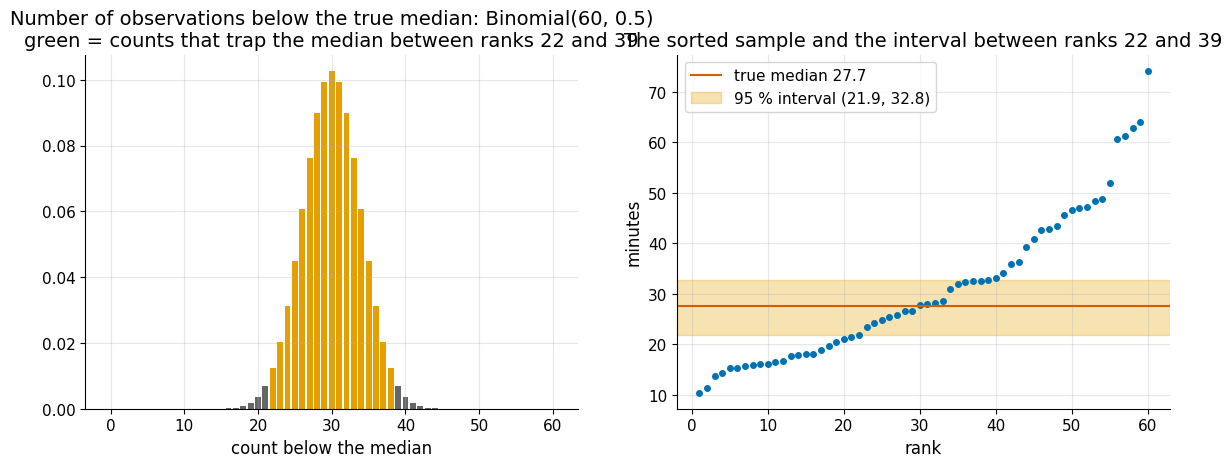

In [19]:
assert abs(coverage(22, 39, 0.5) - 0.9727) < 5e-4 and coverage(23, 38, 0.5) < 0.95 <= coverage(22, 38, 0.5)
# simulation: coverage of the median interval and of the p90 interval over many fresh samples
cov_rng = np.random.default_rng(3)
true_med, true_p90 = np.median(pop), np.percentile(pop, 90)
hit_med = hit_p90 = 0; widths = []
reps = 4000
for _ in range(reps):
    s_ = np.sort(pop[cov_rng.choice(pop.size, 60, replace=False)])
    hit_med += s_[21] <= true_med <= s_[38]; hit_p90 += s_[best[0] - 1] <= true_p90 <= s_[best[1] - 1]; widths.append(s_[38] - s_[21])
print(f"coverage over {reps} samples: median {hit_med / reps:.3f} (exact binomial 0.973), 90th percentile {hit_p90 / reps:.3f} (exact {best[2]:.3f}); average median-interval width {np.mean(widths):.2f}")
assert abs(hit_med / reps - 0.9727) < 0.012 and hit_p90 / reps > 0.93
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
k = np.arange(0, 61)
axes[0].bar(k, stats.binom.pmf(k, 60, 0.5), color=np.where((k >= 22) & (k <= 38), SIM, NEUTRAL))
axes[0].set_title("Number of observations below the true median: Binomial(60, 0.5)\ngreen = counts that trap the median between ranks 22 and 39"); axes[0].set_xlabel("count below the median")
axes[1].plot(np.arange(1, 61), samp, "o", color=MAIN, markersize=4)
axes[1].axhline(true_med, color=HIGHLIGHT, label=f"true median {true_med:.1f}")
axes[1].axhspan(samp[21], samp[38], color=SIM, alpha=0.3, label=f"95 % interval ({samp[21]:.1f}, {samp[38]:.1f})")
axes[1].set_title("The sorted sample and the interval between ranks 22 and 39"); axes[1].set_xlabel("rank"); axes[1].set_ylabel("minutes"); axes[1].legend()
plt.show()

### 11.6b Interpretation and decision (Example 2)
- **Median.** The sample median is **27.9 minutes** and the 95 % interval from the 22nd and 39th sorted values is **(21.9, 32.8)**, which contains the true median 27.7. Its exact coverage is 97.3 % (simulated 97.1 %), a little above 95 % because ranks are whole numbers.
- **90th percentile.** The interval from ranks 50 and 59 is **(46.5, 64.0)**, much wider (17.5 minutes against 10.9) and its coverage is 95.2 % (simulated 95.5 %): extreme quantiles are determined by few points, so they are much less certain than the median.
- **Compared with the bootstrap (05_04).** No resampling and no assumptions are needed here, and the guarantee is exact. The price is some width: the average median-interval width over fresh samples is 10.2 minutes, wider than a bootstrap percentile interval because it is conservative at 97.3 %.
- **Decision.** For a service-level statement use "the median delivery is between 22 and 33 minutes (95 %)". For a promise about 90 % of deliveries collect more data first, since the interval spans 46 to 64 minutes.

---
### Example 3: the 100-year rainfall from 50 years of records

**Scenario.** Daily rainfall on wet-or-dry days is modelled as independent Exponential with mean 10 mm for each of 365 days, so the **annual maximum** is the max of 365 values. A town has **50 years** of annual maxima and must size drainage for the **100-year** level (exceeded with probability 1 % each year). How well can 50 years estimate it?

### 11.7 By hand, in code and by simulation
**By hand (truth).** $P(M_{\text{year}}\le x)=(1-e^{-x/10})^{365}$, so the 100-year level solves this $=0.99$: $x=-10\ln(1-0.99^{1/365})=105.0$ mm. Gumbel: $10(\ln365+4.600)=10(5.900+4.600)=105.0$ mm. With only 50 annual maxima the fitted level carries a large error; we measure it by simulating 1,000 fifty-year records.

true 100-year level: 105.00 mm | Gumbel formula 105.00 mm


GEV (3 parameters): mean 104.4, sd 11.5, 5%-95% range (88.6, 124.9), share below the truth 0.57
Gumbel (2 parameters): mean 104.1, sd 5.7, 5%-95% range (95.2, 114.0), share below the truth 0.59


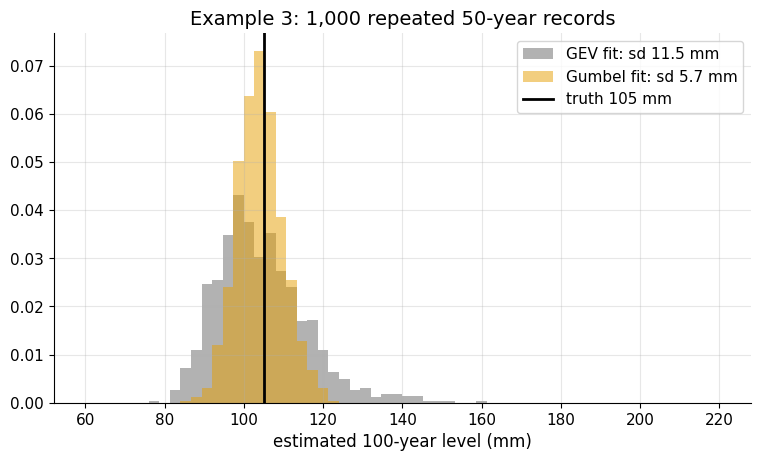

In [20]:
true_100 = -10 * np.log(1 - 0.99 ** (1 / 365))
print(f"true 100-year level: {true_100:.2f} mm | Gumbel formula {10 * (np.log(365) - np.log(-np.log(0.99))):.2f} mm")
ex_rng = np.random.default_rng(81)
records = np.array([ex_rng.exponential(10, (50, 365)).max(axis=1) for _ in range(1000)])          # 1,000 fifty-year records of annual maxima
est = np.empty(1000); est_g = np.empty(1000)
for i, rec in enumerate(records):
    c_, loc, scale = stats.genextreme.fit(rec)
    est[i] = stats.genextreme(c_, loc, scale).isf(0.01)
    loc_g, scale_g = stats.gumbel_r.fit(rec)
    est_g[i] = stats.gumbel_r(loc_g, scale_g).isf(0.01)
for name, e in [("GEV (3 parameters)", est), ("Gumbel (2 parameters)", est_g)]:
    print(f"{name}: mean {e.mean():.1f}, sd {e.std():.1f}, 5%-95% range ({np.percentile(e, 5):.1f}, {np.percentile(e, 95):.1f}), share below the truth {np.mean(e < true_100):.2f}")
assert abs(true_100 - 105.0) < 0.2 and est_g.std() < est.std()
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.hist(est, bins=60, density=True, range=(60, 220), color=NEUTRAL, alpha=0.5, label=f"GEV fit: sd {est.std():.1f} mm")
ax.hist(est_g, bins=60, density=True, range=(60, 220), color=SIM, alpha=0.5, label=f"Gumbel fit: sd {est_g.std():.1f} mm")
ax.axvline(true_100, color="black", linewidth=2, label=f"truth {true_100:.0f} mm")
ax.set_xlabel("estimated 100-year level (mm)"); ax.set_title("Example 3: 1,000 repeated 50-year records"); ax.legend()
plt.show()

### 11.7b Interpretation and decision (Example 3)
- The true 100-year rainfall is **105.0 mm** (the same by the exact formula and by the Gumbel formula). Fitting a three-parameter GEV to 50 years of data gives, on average, 104.4 mm, **but individual 50-year records give anything from 88.6 to 124.9 mm** (90 % of the time; standard deviation 11.5 mm).
- The two-parameter Gumbel fit halves the spread (standard deviation 5.7 mm, 90 % range 95 to 114 mm) because it estimates one parameter fewer, and it is *right* here because the parent is exponential. With real data the tail type is unknown, which is why the GEV is the safer, noisier choice.
- 50 years is only half the return period: the 100-year level is an **extrapolation**, which is why its uncertainty is large.
- **Decision.** Size the drainage for the upper end of the interval (about 125 mm) or collect more information (pool nearby stations, use longer records); do not treat the point estimate as exact.

## 12. Where it is used

### Statistics
- **Nonparametric inference:** distribution-free confidence intervals for medians and quantiles, sign and rank tests, Q-Q plots (plotting positions $k/(n+1)$), tolerance intervals.
- **Extreme-value statistics:** return levels for floods, wind, temperature, insurance losses; the **range** and **studentised range** in quality control.

### Data science
- **Tail latency and SLAs:** p99 of page loads that make many calls ("tail at scale", Example 1); **capacity planning**, worst-case load.
- **Robust summaries** (median, trimmed means, winsorising) and **outlier detection** using the expected maximum; **auction theory** (highest bid, second price).

### ML and AI
- **Top-$k$ and max pooling:** the maximum over many activations or candidates; **beam search** and **best-of-$n$ sampling** (the expected maximum of $n$ scores grows like $\sqrt{2\ln n}$ for Normal scores, which is why sampling more candidates helps less and less).
- **Selection effects and benchmark overfitting:** the best of $K$ models on a validation set is biased upward by about the expected maximum of noise (Module 05_05 union bound); **extreme-value** methods for out-of-distribution detection and for the tails of loss and gradient distributions.

## 13. Common pitfalls and misconceptions

- **The maximum is not Normal.** It converges to Gumbel/Fréchet/Weibull, with a skewed shape; do not use $\bar x\pm1.96\,\mathrm{SE}$ for it.
- **Bootstrap fails for extremes** (05_04): the resample maximum equals the sample maximum in 63 % of resamples. Use the exact order-statistic formulas or an extreme-value model.
- **Ties and discreteness:** the Beta/Binomial results need a continuous parent; with many ties the intervals are conservative.
- **Quantile intervals are discrete:** you cannot hit exactly 95 %; pick the shortest interval with at least that coverage (Example 2: 97.3 %).
- **"100-year" is a probability, not a schedule:** 1 % per year, so a 100-year event has about 63 % chance of occurring at least once in 100 years.
- **Extrapolating beyond the data:** a 50-year record gives a very uncertain 100-year level (Example 3); intervals for return levels are wide.
- **Dependence:** clustered extremes (heat waves, market crashes) break the iid formulas; the *extremal index* corrects it.
- **Median is not always better:** for Normal data it is 57 % less efficient than the mean; its advantage is robustness.

## 14. Exercises

1. For $n=9$ draws from any continuous distribution, what is the probability that the **sample median** exceeds the **true median**? What is $P(X_{(9)}>\text{true median})$?
2. Ten independent components have Exponential lifetimes with mean 1,000 hours and the system fails when the **first** fails. Find the distribution, mean and median of the system lifetime. What if the system works while **at least one** is alive?
3. For $n=40$ observations, find the ranks $(l,u)$ of the shortest distribution-free interval for the **median** with coverage at least 95 %, and the exact coverage.
4. Show by simulation that for $n=25$ Uniform(0,1) draws the range has mean $(n-1)/(n+1)$ and compare with the Beta($n-1$, 2) distribution.
5. How large must $n$ be for the maximum of $n$ standard Normals to exceed 4 with probability at least 50 %? Compare with the $\sqrt{2\ln n}$ rule.
6. (Harder) Estimate by simulation the 50-year return level of the annual maximum of Exercise 5's Normal parent with 365 days, and compare the Gumbel and GEV fits from 50 simulated years.

Solutions are at the end.

## 15. Summary table

| Question | Tool | Formula | Caveat |
|---|---|---|---|
| Distribution of the max / min | order statistics | $F^n$, $1-(1-F)^n$ | iid |
| Where does the $k$-th value fall? | Beta on probability scale | $F(X_{(k)})\sim\mathrm{Beta}(k,n-k+1)$ | continuous $F$ |
| CI for a quantile | Binomial ranks | $P(l\le B\le u-1)$, $B\sim\mathrm{Bin}(n,p)$ | discrete coverage |
| SE of the median | asymptotic | $1/(2f(\xi)\sqrt n)$ | needs $f(\xi)>0$ |
| Extremes of many values | GEV | Gumbel, Fréchet, Weibull | slow convergence, dependence |
| Rare level | return level | $F^{-1}(1-1/T)$ | extrapolation is uncertain |

## Solutions

In [21]:
print("1: P(sample median > true median) = P(Bin(9, .5) >= 5) =", round(stats.binom.sf(4, 9, 0.5), 4), "= 1/2 (symmetry); P(X_(9) > true median) = 1 - 0.5^9 =", round(1 - 0.5**9, 5))
print("2: first failure ~ Exponential(mean 100): mean 100 h, median", round(100 * np.log(2), 2), "h | last failure: mean", round(1000 * np.sum(1 / np.arange(1, 11)), 1), "h, median", round(-1000 * np.log(1 - 0.5 ** (1 / 10)), 1), "h")
best3 = None
for l in range(1, 41):
    for u in range(l + 1, 41):
        c = stats.binom.cdf(u - 1, 40, 0.5) - stats.binom.cdf(l - 1, 40, 0.5)
        if c >= 0.95 and (best3 is None or u - l < best3[1] - best3[0] or (u - l == best3[1] - best3[0] and c > best3[2])):
            best3 = (l, u, c)
print("3: ranks", best3[:2], "coverage", round(best3[2], 4))
r25 = np.ptp(rng.uniform(size=(100_000, 25)), axis=1)
print("4: simulated mean range", round(r25.mean(), 4), "| (n-1)/(n+1) =", round(24 / 26, 4), "| KS p-value vs Beta(24, 2):", round(stats.kstest(r25, stats.beta(24, 2).cdf).pvalue, 3))
n_need = int(np.ceil(np.log(0.5) / np.log(stats.norm.cdf(4))))
print("5: n needed for P(max > 4) >= 0.5:", n_need, "| sqrt(2 ln n) at that n =", round(np.sqrt(2 * np.log(n_need)), 3), "(the simple rule overshoots by about 0.4: the true expected maximum there is near 4.0)")
ann = rng.normal(size=(5000, 365)).max(axis=1)
est_gev = stats.genextreme(*stats.genextreme.fit(ann)).isf(1 / 50)
true50 = stats.norm.isf(1 - 0.98 ** (1 / 365))
print("6: true 50-year level of the annual maximum:", round(true50, 3), "| from 5,000 simulated years (GEV fit):", round(est_gev, 3))
fit50 = []
for _ in range(300):
    s50 = rng.normal(size=(50, 365)).max(axis=1)
    fit50.append((stats.gumbel_r(*stats.gumbel_r.fit(s50)).isf(1 / 50), stats.genextreme(*stats.genextreme.fit(s50)).isf(1 / 50)))
fit50 = np.array(fit50)
print("   from 50 years: Gumbel mean", fit50[:, 0].mean().round(3), "sd", fit50[:, 0].std().round(3), "| GEV mean", fit50[:, 1].mean().round(3), "sd", fit50[:, 1].std().round(3))

1: P(sample median > true median) = P(Bin(9, .5) >= 5) = 0.5 = 1/2 (symmetry); P(X_(9) > true median) = 1 - 0.5^9 = 0.99805
2: first failure ~ Exponential(mean 100): mean 100 h, median 69.31 h | last failure: mean 2929.0 h, median 2703.6 h


3: ranks (14, 27) coverage 0.9615
4: simulated mean range 0.923 | (n-1)/(n+1) = 0.9231 | KS p-value vs Beta(24, 2): 0.726
5: n needed for P(max > 4) >= 0.5: 21886 | sqrt(2 ln n) at that n = 4.471 (the simple rule overshoots by about 0.4: the true expected maximum there is near 4.0)


6: true 50-year level of the annual maximum: 3.866 | from 5,000 simulated years (GEV fit): 3.86


   from 50 years: Gumbel mean 3.998 sd 0.148 | GEV mean 3.844 sd 0.183


**1.** $P=P(\mathrm{Bin}(9,\tfrac12)\ge5)=\tfrac12$: the sample median exceeds the true median exactly when at least 5 of the 9 observations do (symmetry of the Binomial). The maximum exceeds the true median unless all nine fall below it: $1-0.5^9=0.998$.

**2.** The first failure is Exponential with mean $1000/10=100$ h (median $100\ln2=69.3$ h). The last failure has mean $1000\sum_{i=1}^{10}1/i=2{,}929$ h and median $2{,}704$ h: a parallel system lives about 29 times longer than a series system.

**3.** Ranks $(14,27)$ with exact coverage **0.9615** (symmetric around the middle rank 20.5).

**4.** Simulated mean range 0.923 against $(n-1)/(n+1)=0.9231$, and the Kolmogorov-Smirnov test against Beta(24, 2) has $p=0.73$: the Beta law fits.

**5.** $\Phi(4)^n=0.5$ gives $n=21{,}886$ (about 22,000). The simple rule $\sqrt{2\ln n}=4.47$ **overshoots** (the true expected maximum there is about 4.0) because the convergence is slow.

**6.** The true 50-year level of the annual maximum of 365 standard Normals is 3.866 (a 5,000-year GEV fit gives 3.86). From 50 years: the Gumbel fit averages **3.998** (biased up by 0.13) with standard deviation 0.148, the GEV fit averages **3.844** (bias $-0.02$) with standard deviation 0.183. Normal maxima approach the Gumbel only slowly (the true tail is a little lighter), so the simpler model is biased but steadier and the GEV is nearly unbiased but noisier: a bias-variance trade-off.